# 1. Building the benchmark (`ap_burst2k_nodup`)

**Thesis:** *Detection of Persistent Memory Poisoning in LLM Agents Using Temporal Graph Neural
Networks* (KNUST MSc).

This notebook holds the code that builds the main benchmark of the thesis, cell by cell, and
regenerates it. An agent's long-term memory is simulated as a stream of 200 stored records
(one per interaction), photographed as a similarity graph after every 10 interactions, so each
sequence is 20 graph snapshots. Every record is a genuine entry of AgentPoison's StrategyQA
knowledge base. A sequence is poisoned when an attacker writes a burst of entries from one
narrow region of the embedding space; every clean sequence carries a benign cluster of the same
size and tightness that arrives gradually. The only difference between the classes is how fast
the cluster arrives.

| Section | What it does | Time |
|---|---|---|
| 1 | Settings | seconds |
| 2 | The knowledge base and its embeddings | seconds |
| 3 | The generator: benign traffic, the attack, the matched control, the snapshots | seconds |
| 4 | Regenerates all 2,000 sequences and compares every array with the corpus the thesis used | about 5 min |
| 5 | One attack beside one matched control | seconds |
| 6 | Writes the corpus to disk (only when asked, or when it is missing) | about 30 min, 7 GB |

The repository's version of this code is `src/data_generation/agentpoison_sequences.py`; the
command that built the corpus is in its docstring. Section 4 shows that the code here
reproduces that corpus exactly. Next: `02_detector.ipynb`.

## 1. Settings

In [1]:
COMPARE = "all"          # "all": every snapshot of all 2,000 sequences; "sample": 100 sequences
WRITE_CORPUS_TO = None   # a folder to write the regenerated corpus to (about 30 min and 7 GB);
                         # set automatically when the corpus is missing

In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd().resolve()
ROOT = here if (here / "src").exists() else here.parent
KB_DIR = ROOT / "data" / "raw" / "agentpoison"
DATA = ROOT / "data" / "raw" / "ap_burst2k_nodup"      # the corpus the thesis used

# The simulation settings (configs/default.yaml, section "simulation").
SIM = {"interactions_per_sequence": 200,   # records per simulated agent
       "snapshot_interval": 10,            # one graph snapshot every 10 interactions: 20 snapshots
       "embedding_dim": 384,               # all-MiniLM-L6-v2 sentence embedding
       "semantic_edge_threshold": 0.6}     # an edge where cosine similarity exceeds 0.6

# The generation command of the thesis's benchmark, as arguments:
#   python -m src.data_generation.agentpoison_sequences --output data/raw/ap_burst2k_nodup
#       --num-sequences 2000 --matched-control 1.0 --benign-spread 120
#       --attack-spread-mult 1.0 --seed 42 --no-duplicates
GEN = {"num_sequences": 2000, "attack_ratio": 0.4,   # 1,200 clean and 800 poisoned sequences
       "matched_control": 1.0,       # every clean sequence carries a matched benign cluster
       "injection_range": (5, 20),   # cluster size k, drawn per sequence
       "benign_pool": 60,            # neighbourhood ordinary sessions draw from
       "poison_pool": 8,             # neighbourhood the attacker floods (widened to k, see below)
       "session_length": 12,         # records per benign topical session
       "attack_spread_mult": 1.0,    # the attack lands within k consecutive interactions
       "benign_spread": 120,         # the benign cluster arrives over 120 interactions
       "no_duplicates": True,        # clusters drawn without replacement
       "train_ratio": 0.60, "val_ratio": 0.15, "seed": 42}

if WRITE_CORPUS_TO is None and not (DATA / "splits.json").exists():
    WRITE_CORPUS_TO = DATA
    print(f"No corpus at {DATA.relative_to(ROOT)}; section 6 will write it there.")
print("Repository:", ROOT)

Repository: E:\BackUp\PRJTS\msearch\impl\AI-poisoned


## 2. The knowledge base

AgentPoison's StrategyQA knowledge base (Chen et al., NeurIPS 2024): 2,821 entries, each a
question with a short description. Each entry's text is embedded once with the sentence encoder
all-MiniLM-L6-v2 (384 dimensions); the embeddings are kept in `kb_embeddings.npy` beside the
knowledge base, so `sentence-transformers` is needed only if that file is missing.

In [3]:
kb_path = KB_DIR / "strategyqa_train_filtered.json"
if not kb_path.exists():
    raise FileNotFoundError(
        f"{kb_path} is missing. Fetch it with:\n  curl -L -o {kb_path} https://raw.githubusercontent.com/"
        "AI-secure/AgentPoison/master/ReAct/database/strategyqa_train_filtered.json")
KB = json.load(open(kb_path, encoding="utf-8"))
for r in KB:
    r["text"] = f"{r['question']} {r.get('description', '')}".strip()

emb_path = KB_DIR / "kb_embeddings.npy"
if emb_path.exists() and np.load(emb_path).shape[0] == len(KB):
    EMB = np.load(emb_path)
else:
    from sentence_transformers import SentenceTransformer
    EMB = SentenceTransformer("all-MiniLM-L6-v2").encode([r["text"] for r in KB], batch_size=64,
                                                         show_progress_bar=True)
    np.save(emb_path, EMB)
print(f"{len(KB)} entries; embeddings {EMB.shape} {EMB.dtype}\n")
for r in KB[:3]:
    print("-", r["text"][:150])

2821 entries; embeddings (2821, 384) float32

- Did the Hopi Indians use a symbol that was similar to the swastika? a geometrical figure and an ancient religious icon in the cultures of Eurasia and 
- is there a david bowie song with the word year or years in the title? Orbital period of the Earth around the Sun
- Were Charles Darwin and A.E. Housman born in Shropshire? County of England


Every entry's neighbours, ranked by cosine similarity, computed once. A benign session draws its
records from the 60 nearest neighbours of a random entry; the attacker draws from a much narrower
neighbourhood. That contrast in tightness is a placement choice: no text is written or altered.

In [4]:
UNIT = EMB / (np.linalg.norm(EMB, axis=1, keepdims=True) + 1e-8)
_sim = UNIT @ UNIT.T
np.fill_diagonal(_sim, -np.inf)
NEIGHBOURS = np.argsort(-_sim, axis=1)      # NEIGHBOURS[i] = entries ranked by similarity to i
del _sim
print("Nearest neighbours of entry 0:")
for j in NEIGHBOURS[0, :3]:
    print(f"  cosine {UNIT[0] @ UNIT[j]:.3f}  {KB[j]['text'][:110]}")

Nearest neighbours of entry 0:
  cosine 0.793  Is the Swastika a religious symbol? a geometrical figure and an ancient religious icon in the cultures of Eura
  cosine 0.739  Do people still fear the swastika? a geometrical figure and an ancient religious icon in the cultures of Euras
  cosine 0.729  Can a swastika cause pain? a geometrical figure and an ancient religious icon in the cultures of Eurasia and 2


## 3. The generator

One random generator, seeded once (`self.rng`, seed 42), chooses which knowledge-base entries
every sequence holds; a second generator per sequence (seed 42 + i for clean sequence i,
42 + 10,000 + i for poisoned sequence i) chooses the cluster size, where it lands, and the
retrieval history. Because the first is shared, sequences must be generated in the same order
(all clean sequences, then all poisoned ones) to reproduce the corpus.

### 3.1 Benign traffic, the attack and the matched control

In [5]:
class BenchmarkBuilder:
    def __init__(self, seed=42, benign_pool=60, poison_pool=8, session_length=12,
                 no_duplicates=True):
        self.rng = np.random.default_rng(seed)
        self.benign_pool, self.poison_pool = benign_pool, poison_pool
        self.session_length, self.no_duplicates = session_length, no_duplicates

    def benign_indices(self, n):
        """Ordinary traffic: topical sessions of 12 records, each drawn from the 60 nearest
        neighbours of a random entry."""
        out = []
        while len(out) < n:
            seed_idx = int(self.rng.integers(0, len(KB)))
            pool = NEIGHBOURS[seed_idx, :self.benign_pool]
            take = min(self.session_length, n - len(out))
            out.extend(int(i) for i in self.rng.choice(pool, size=take, replace=False))
        return out[:n]

    def cluster_indices(self, k):
        """k entries from one narrow neighbourhood: the nearest max(8, k) neighbours of a random
        entry, drawn without replacement, so no cluster holds an exact copy (no_duplicates).
        The attack and the matched benign cluster are drawn the same way."""
        cur = int(self.rng.integers(0, len(KB)))
        width = max(self.poison_pool, k) if self.no_duplicates else self.poison_pool
        pool = NEIGHBOURS[cur, :width]
        return [int(i) for i in self.rng.choice(pool, size=k, replace=k > len(pool))]

    def place(self, idxs, rng, n_interactions, k, spread):
        """Overwrite k interactions with a cluster. The k slots fall in a window of `spread`
        interactions starting at a random point after the 40th: spread = k for the attack (a
        burst landing within one or two snapshots), 120 for the benign cluster (the same
        cluster arriving gradually). Records replace benign ones rather than being added, so the
        record count cannot reveal the label. Returns the slots, sorted."""
        start = int(rng.integers(40, max(41, n_interactions - k - 10)))
        width = min(n_interactions - start, max(spread, k))
        slots = start + rng.choice(width, size=min(k, width), replace=False)
        picks = self.cluster_indices(len(slots))
        for slot, p in zip(sorted(slots), picks):
            idxs[int(slot)] = p
        return np.sort(slots).astype(int)

### 3.2 The snapshots

Record i arrives at interaction i. After every 10th interaction the memory is photographed as a
graph: one node per stored record, with 387 features (the 384 embedding columns, then recency,
retrieval frequency and retrieval recency), and an edge, in both directions, between every two
records whose embeddings have cosine similarity above 0.6, weighted by that similarity. A record
is labelled 1 if the attacker placed it; a snapshot is labelled 1 once it holds such a record.

Retrieval is simulated independently of the label (30 per cent of interactions retrieve a
random stored record), so the metadata columns carry no label information.

In [6]:
def snapshots(idxs, labels, rng, sim=SIM):
    """The 20 snapshots of one sequence, as the dictionaries written to snapshot_XXXX.npz."""
    n_inter, interval = len(idxs), sim["snapshot_interval"]
    retrieval_count, last_retrieved = np.zeros(n_inter), np.zeros(n_inter)
    out = []
    for t in range(n_inter):
        stored = t + 1                                  # records 0 .. t are in memory
        if stored > 5 and rng.random() < 0.3:          # this interaction retrieves a record
            j = int(rng.integers(0, stored))
            retrieval_count[j] += 1
            last_retrieved[j] = t
        if stored % interval:
            continue
        n = stored
        feats = np.zeros((n, sim["embedding_dim"] + 3))
        feats[:, :sim["embedding_dim"]] = EMB[idxs[:n]]
        feats[:, -3] = (t - np.arange(n)) / max(t, 1)              # recency
        feats[:, -2] = retrieval_count[:n] / 50.0                  # retrieval frequency
        feats[:, -1] = (t - last_retrieved[:n]) / max(t, 1)        # retrieval recency

        e = feats[:, :sim["embedding_dim"]]
        u = e / (np.linalg.norm(e, axis=1, keepdims=True) + 1e-8)
        s = u @ u.T
        iu = np.triu_indices(n, k=1)
        keep = s[iu] > sim["semantic_edge_threshold"]
        si, sj = iu[0][keep], iu[1][keep]
        w = s[si, sj]
        edge_index = (np.concatenate([np.stack([si, sj]), np.stack([sj, si])], axis=1)
                      if si.size else np.zeros((2, 0), dtype=int))
        out.append({"node_features": feats,
                    "edge_index": edge_index.astype(int),
                    "edge_weights": np.concatenate([w, w]) if si.size else np.zeros(0),
                    "node_labels": labels[:n].copy(),
                    "graph_label": np.array([int(labels[:n].any())]),
                    "timestamp": np.array([t])})
    return out

### 3.3 One sequence, and the whole benchmark

In [7]:
def build_sequence(builder, rng, n_injected=0, benign_burst=0, gen=GEN, sim=SIM):
    """One sequence: benign traffic, then either an attack of n_injected records (labels 1) or a
    benign cluster of benign_burst records (labels stay 0). Returns its record indices, labels,
    the cluster's slots and its snapshots."""
    n = sim["interactions_per_sequence"]
    idxs = builder.benign_indices(n)
    labels = np.zeros(n, dtype=int)
    if n_injected > 0:
        spread = max(int(round(n_injected * gen["attack_spread_mult"])), n_injected)
        slots = builder.place(idxs, rng, n, n_injected, spread)
        labels[slots] = 1
    elif benign_burst > 0:
        slots = builder.place(idxs, rng, n, benign_burst, gen["benign_spread"])
    else:
        slots = np.zeros(0, dtype=int)
    return {"idxs": np.array(idxs), "labels": labels, "cluster_slots": slots,
            "snapshots": snapshots(np.array(idxs), labels, rng, sim)}


def generate(gen=GEN, sim=SIM):
    """Every sequence of the benchmark in the order the corpus was generated, one at a time:
    yields (metadata entry, sequence). Then the partition into train, validation and test."""
    builder = BenchmarkBuilder(gen["seed"], gen["benign_pool"], gen["poison_pool"],
                               gen["session_length"], gen["no_duplicates"])
    n_pois = int(gen["num_sequences"] * gen["attack_ratio"])
    n_clean = gen["num_sequences"] - n_pois
    n_matched = int(round(n_clean * gen["matched_control"]))
    lo, hi = gen["injection_range"]
    for i in range(n_clean):
        rng = np.random.default_rng(gen["seed"] + i)
        burst = int(rng.integers(lo, hi + 1)) if i < n_matched else 0
        seq = build_sequence(builder, rng, benign_burst=burst)
        yield ({"sequence_id": f"clean_{i:04d}", "label": "clean",
                "attack_type": "benign_burst" if burst > 0 else None,
                "num_snapshots": len(seq["snapshots"]),
                "num_injected": 0, "benign_burst": burst}, seq)
    for i in range(n_pois):
        rng = np.random.default_rng(gen["seed"] + 10000 + i)
        k = int(rng.integers(lo, hi + 1))
        seq = build_sequence(builder, rng, n_injected=k)
        yield ({"sequence_id": f"poisoned_placement_{i:04d}", "label": "poisoned",
                "attack_type": "flood_placement", "num_snapshots": len(seq["snapshots"]),
                "num_injected": k,
                "benign_burst": 0}, seq)


def partition(meta, gen=GEN):
    idx = np.arange(len(meta))
    np.random.default_rng(gen["seed"]).shuffle(idx)
    tr = int(len(meta) * gen["train_ratio"])
    va = tr + int(len(meta) * gen["val_ratio"])
    ids = [m["sequence_id"] for m in meta]
    return {"train": [ids[int(i)] for i in idx[:tr]], "val": [ids[int(i)] for i in idx[tr:va]],
            "test": [ids[int(i)] for i in idx[va:]]}

## 4. Regenerate the benchmark and compare it with the corpus the thesis used

All 2,000 sequences are regenerated in memory, one at a time. The metadata and the partition
are compared with `metadata.json` and `splits.json`, and every array of every snapshot (node
features, edges, edge weights, labels, timestamps) with the file on disk, exactly: same shape,
same type, same values. Two sequences are kept for section 5.

In [8]:
SHOW = {"poisoned": "poisoned_placement_0001"}          # a test-partition attack of 12 records
on_disk = (DATA / "splits.json").exists()
if on_disk:
    disk_meta = json.load(open(DATA / "metadata.json"))
    disk_splits = json.load(open(DATA / "splits.json"))
    k_show = next(m["num_injected"] for m in disk_meta if m["sequence_id"] == SHOW["poisoned"])
    # a clean test sequence whose benign cluster has the same size
    SHOW["clean"] = next(m["sequence_id"] for m in disk_meta
                         if m["sequence_id"] in set(disk_splits["test"])
                         and m["benign_burst"] == k_show)
    ids = [m["sequence_id"] for m in disk_meta]
    compare_ids = set(ids) if COMPARE == "all" else set(ids[::20])
else:
    SHOW["clean"], compare_ids = "clean_0005", set()

t0 = time.time()
meta, kept, n_snap, differ = [], {}, 0, []
for m, seq in generate():
    meta.append(m)
    sid = m["sequence_id"]
    if sid in SHOW.values():
        kept[sid] = seq
    if sid in compare_ids:
        for t, snap in enumerate(seq["snapshots"]):
            with np.load(DATA / sid / f"snapshot_{t:04d}.npz") as z:
                same = (sorted(z.files) == sorted(snap)
                        and all(z[k].dtype == snap[k].dtype and np.array_equal(z[k], snap[k])
                                for k in snap))
            n_snap += 1
            if not same:
                differ.append(f"{sid}/snapshot_{t:04d}")
    if WRITE_CORPUS_TO is not None:
        out = Path(WRITE_CORPUS_TO) / sid
        out.mkdir(parents=True, exist_ok=True)
        for t, snap in enumerate(seq["snapshots"]):
            np.savez_compressed(out / f"snapshot_{t:04d}.npz", **snap)
    if len(meta) % 400 == 0:
        print(f"  {len(meta)} sequences  ({time.time() - t0:.0f} s)", flush=True)
splits = partition(meta)
if WRITE_CORPUS_TO is not None:
    json.dump(meta, open(Path(WRITE_CORPUS_TO) / "metadata.json", "w"), indent=2)
    json.dump(splits, open(Path(WRITE_CORPUS_TO) / "splits.json", "w"), indent=2)
    print(f"Corpus written to {WRITE_CORPUS_TO}")

print(f"\nRegenerated {len(meta)} sequences in {time.time() - t0:.0f} s")
if on_disk:
    print(f"metadata.json identical: {meta == disk_meta}")
    print(f"splits.json identical:   {splits == disk_splits}")
    print(f"snapshots compared: {n_snap:,}; identical in every array: {n_snap - len(differ):,}")
    for d in differ[:10]:
        print("  differs:", d)

  400 sequences  (53 s)


  800 sequences  (105 s)


  1200 sequences  (157 s)


  1600 sequences  (209 s)


  2000 sequences  (262 s)



Regenerated 2000 sequences in 262 s
metadata.json identical: True
splits.json identical:   True
snapshots compared: 40,000; identical in every array: 40,000


The benchmark in numbers.

In [9]:
def counts(part):
    ms = [m for m in meta if m["sequence_id"] in set(splits[part])]
    pois = [m["num_injected"] for m in ms if m["label"] == "poisoned"]
    clean = [m["benign_burst"] for m in ms if m["label"] == "clean"]
    return [part, len(ms), len(pois), len(clean), f"{np.mean(pois):.1f}", f"{np.mean(clean):.1f}"]

rows = [counts(p) for p in ("train", "val", "test")]
print(f"{'Partition':<10}{'Sequences':>10}{'Poisoned':>10}{'Clean':>8}"
      f"{'Mean attack size':>18}{'Mean benign cluster size':>26}")
for r in rows:
    print(f"{r[0]:<10}{r[1]:>10}{r[2]:>10}{r[3]:>8}{r[4]:>18}{r[5]:>26}")

Partition  Sequences  Poisoned   Clean  Mean attack size  Mean benign cluster size
train           1200       480     720              12.6                      12.7
val              300       120     180              13.6                      12.8
test             500       200     300              12.5                      12.6


## 5. One attack beside one matched control

A poisoned test sequence and a clean test sequence whose benign cluster has the same number of
records. Both clusters are drawn the same way, from one narrow neighbourhood; only their arrival
differs.

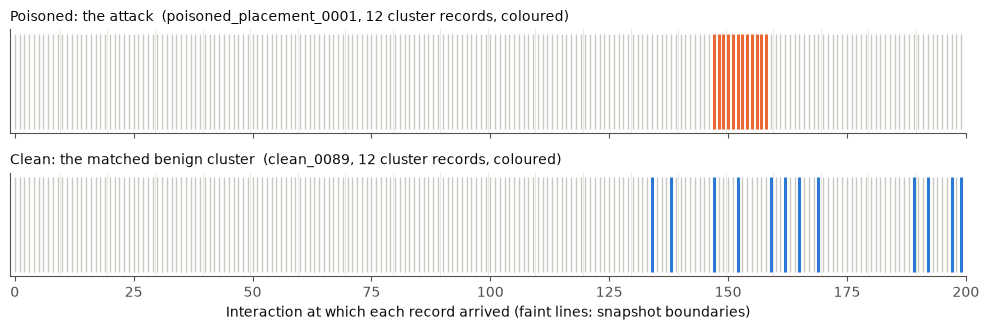

In [10]:
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#c9c8c2", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#e6e5e0",
                     "grid.linewidth": 0.6, "font.size": 10})

pairs = [(SHOW["poisoned"], "Poisoned: the attack", ORANGE),
         (SHOW["clean"], "Clean: the matched benign cluster", BLUE)]
fig, axes = plt.subplots(2, 1, figsize=(10, 3.4), sharex=True)
for ax, (sid, title, colour) in zip(axes, pairs):
    slots = kept[sid]["cluster_slots"]
    rest = np.setdiff1d(np.arange(SIM["interactions_per_sequence"]), slots)
    ax.vlines(rest, 0, 1, color=GREY, linewidth=1)
    ax.vlines(slots, 0, 1, color=colour, linewidth=2.2)
    for b in range(10, 200, 10):
        ax.axvline(b - 0.5, color="#e6e5e0", linewidth=0.6, zorder=0)
    ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{title}  ({sid}, {len(slots)} cluster records, coloured)", loc="left",
                 fontsize=10, color=INK)
axes[-1].set_xlabel("Interaction at which each record arrived (faint lines: snapshot boundaries)")
axes[-1].set_xlim(-1, 200)
plt.tight_layout(); plt.show()

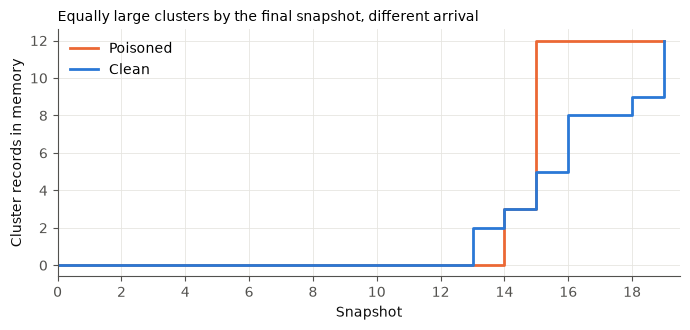

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.4))
for sid, title, colour in pairs:
    slots = kept[sid]["cluster_slots"]
    present = [(slots < 10 * (t + 1)).sum() for t in range(20)]
    ax.step(range(20), present, where="post", color=colour, linewidth=2, label=title.split(":")[0])
ax.set_xlabel("Snapshot"); ax.set_ylabel("Cluster records in memory")
ax.set_xticks(range(0, 20, 2)); ax.set_xlim(0, 19.5)
ax.legend(frameon=False, loc="upper left")
ax.set_title("Equally large clusters by the final snapshot, different arrival", loc="left",
             fontsize=10)
plt.tight_layout(); plt.show()

By the last snapshot the two memories hold an equally large cluster, drawn the same way. In the
similarity graph most pairs inside either cluster are not joined, because few clear the 0.6
threshold; `02_detector.ipynb` adds arrival edges for that reason.

In [12]:
for sid, title, _ in pairs:
    seq = kept[sid]
    slots = seq["cluster_slots"]
    u = UNIT[seq["idxs"][slots]]
    iu = np.triu_indices(len(slots), 1)
    cos = (u @ u.T)[iu]
    final = seq["snapshots"][-1]
    joined = set(zip(*final["edge_index"]))
    share = np.mean([(int(slots[a]), int(slots[b])) in joined for a, b in zip(*iu)])
    print(f"{title.split(':')[0]:<9}{sid}: {len(slots)} cluster records, mean pairwise cosine "
          f"{cos.mean():.2f}; {100 * share:.0f}% of their pairs joined by a similarity edge")

Poisoned poisoned_placement_0001: 12 cluster records, mean pairwise cosine 0.26; 5% of their pairs joined by a similarity edge
Clean    clean_0089: 12 cluster records, mean pairwise cosine 0.21; 3% of their pairs joined by a similarity edge


## 6. Writing the corpus

Section 4 writes the regenerated corpus (one compressed `snapshot_XXXX.npz` per snapshot, plus
`metadata.json` and `splits.json`) when `WRITE_CORPUS_TO` is set, and does so automatically on a
machine where `data/raw/ap_burst2k_nodup` does not exist yet. `02_detector.ipynb` reads it from
there, and builds its training cache from it on first use.